In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

In [2]:
# CARREGAMENTO DOS DADOS
df = pd.read_csv('melb_data.csv')

print(df.head())

       Suburb           Address  Rooms Type      Price Method SellerG  \
0  Abbotsford      85 Turner St      2    h  1480000.0      S  Biggin   
1  Abbotsford   25 Bloomburg St      2    h  1035000.0      S  Biggin   
2  Abbotsford      5 Charles St      3    h  1465000.0     SP  Biggin   
3  Abbotsford  40 Federation La      3    h   850000.0     PI  Biggin   
4  Abbotsford       55a Park St      4    h  1600000.0     VB  Nelson   

        Date  Distance  Postcode  ...  Bathroom  Car  Landsize  BuildingArea  \
0  3/12/2016       2.5    3067.0  ...       1.0  1.0     202.0           NaN   
1  4/02/2016       2.5    3067.0  ...       1.0  0.0     156.0          79.0   
2  4/03/2017       2.5    3067.0  ...       2.0  0.0     134.0         150.0   
3  4/03/2017       2.5    3067.0  ...       2.0  1.0      94.0           NaN   
4  4/06/2016       2.5    3067.0  ...       1.0  2.0     120.0         142.0   

   YearBuilt  CouncilArea Lattitude  Longtitude             Regionname  \
0     

In [5]:
# DIAGNÓSTICO INICIAL
print("Dimensões do dataset:")
print(df.shape)

print("\nTipos de dados:")
print(df.dtypes)

print("\nValores ausentes por coluna:")
print(df.isnull().sum())

Dimensões do dataset:
(13580, 21)

Tipos de dados:
Suburb               str
Address              str
Rooms              int64
Type                 str
Price            float64
Method               str
SellerG              str
Date                 str
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea          str
Lattitude        float64
Longtitude       float64
Regionname           str
Propertycount    float64
dtype: object

Valores ausentes por coluna:
Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
Lattit

In [6]:
# RESUMO DE VALORES AUSENTES (QUANTIDADE E %)
quantidade = df.isnull().sum()

porcentagem = df.isnull().mean() * 100

resumo = pd.DataFrame({
    'Quantidade': quantidade,
    'Porcentagem': porcentagem
})

print(resumo)

               Quantidade  Porcentagem
Suburb                  0     0.000000
Address                 0     0.000000
Rooms                   0     0.000000
Type                    0     0.000000
Price                   0     0.000000
Method                  0     0.000000
SellerG                 0     0.000000
Date                    0     0.000000
Distance                0     0.000000
Postcode                0     0.000000
Bedroom2                0     0.000000
Bathroom                0     0.000000
Car                    62     0.456554
Landsize                0     0.000000
BuildingArea         6450    47.496318
YearBuilt            5375    39.580265
CouncilArea          1369    10.081001
Lattitude               0     0.000000
Longtitude              0     0.000000
Regionname              0     0.000000
Propertycount           0     0.000000


In [7]:
# Ordena da maior quantidade para a menor
resumo = resumo.sort_values(
    by='Quantidade', ascending=False
)

print("\nResumo de valores ausentes:")
print(resumo.round(2))


Resumo de valores ausentes:
               Quantidade  Porcentagem
BuildingArea         6450        47.50
YearBuilt            5375        39.58
CouncilArea          1369        10.08
Car                    62         0.46
Suburb                  0         0.00
Price                   0         0.00
Type                    0         0.00
Rooms                   0         0.00
Address                 0         0.00
Distance                0         0.00
Method                  0         0.00
Date                    0         0.00
SellerG                 0         0.00
Bathroom                0         0.00
Bedroom2                0         0.00
Postcode                0         0.00
Landsize                0         0.00
Lattitude               0         0.00
Longtitude              0         0.00
Regionname              0         0.00
Propertycount           0         0.00


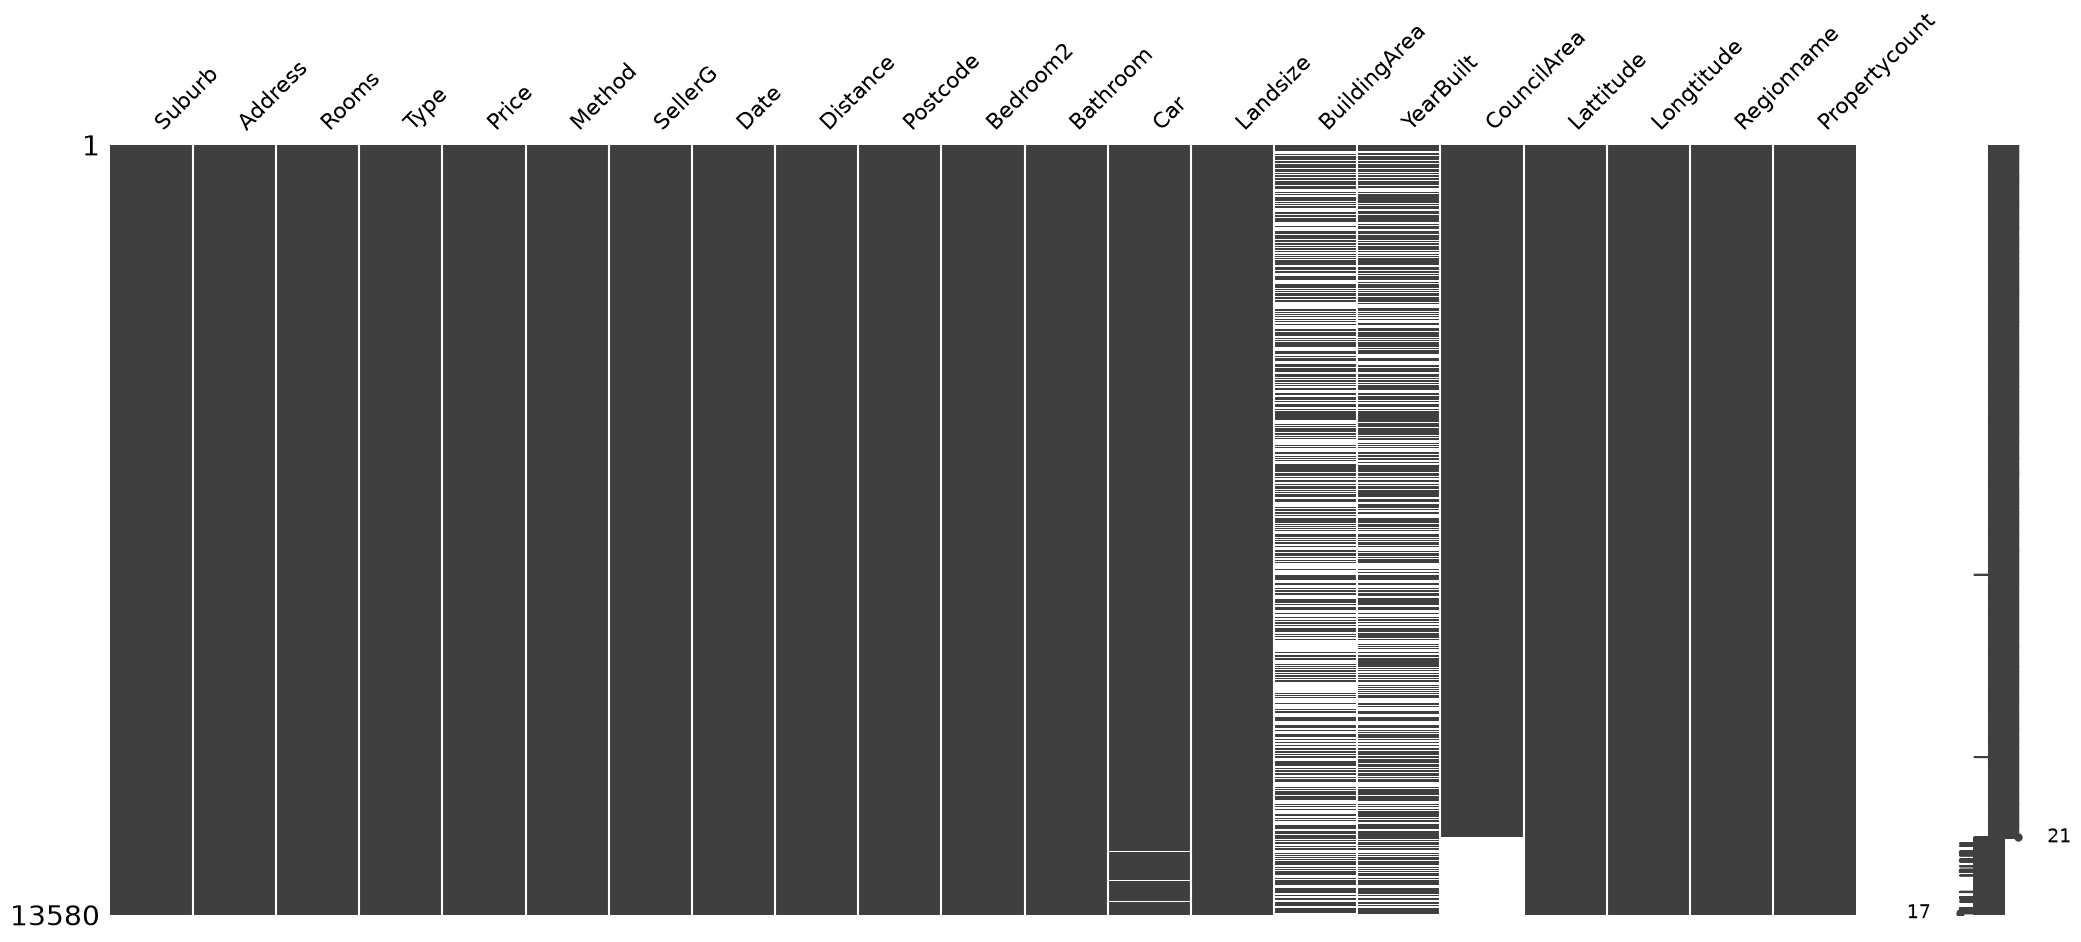

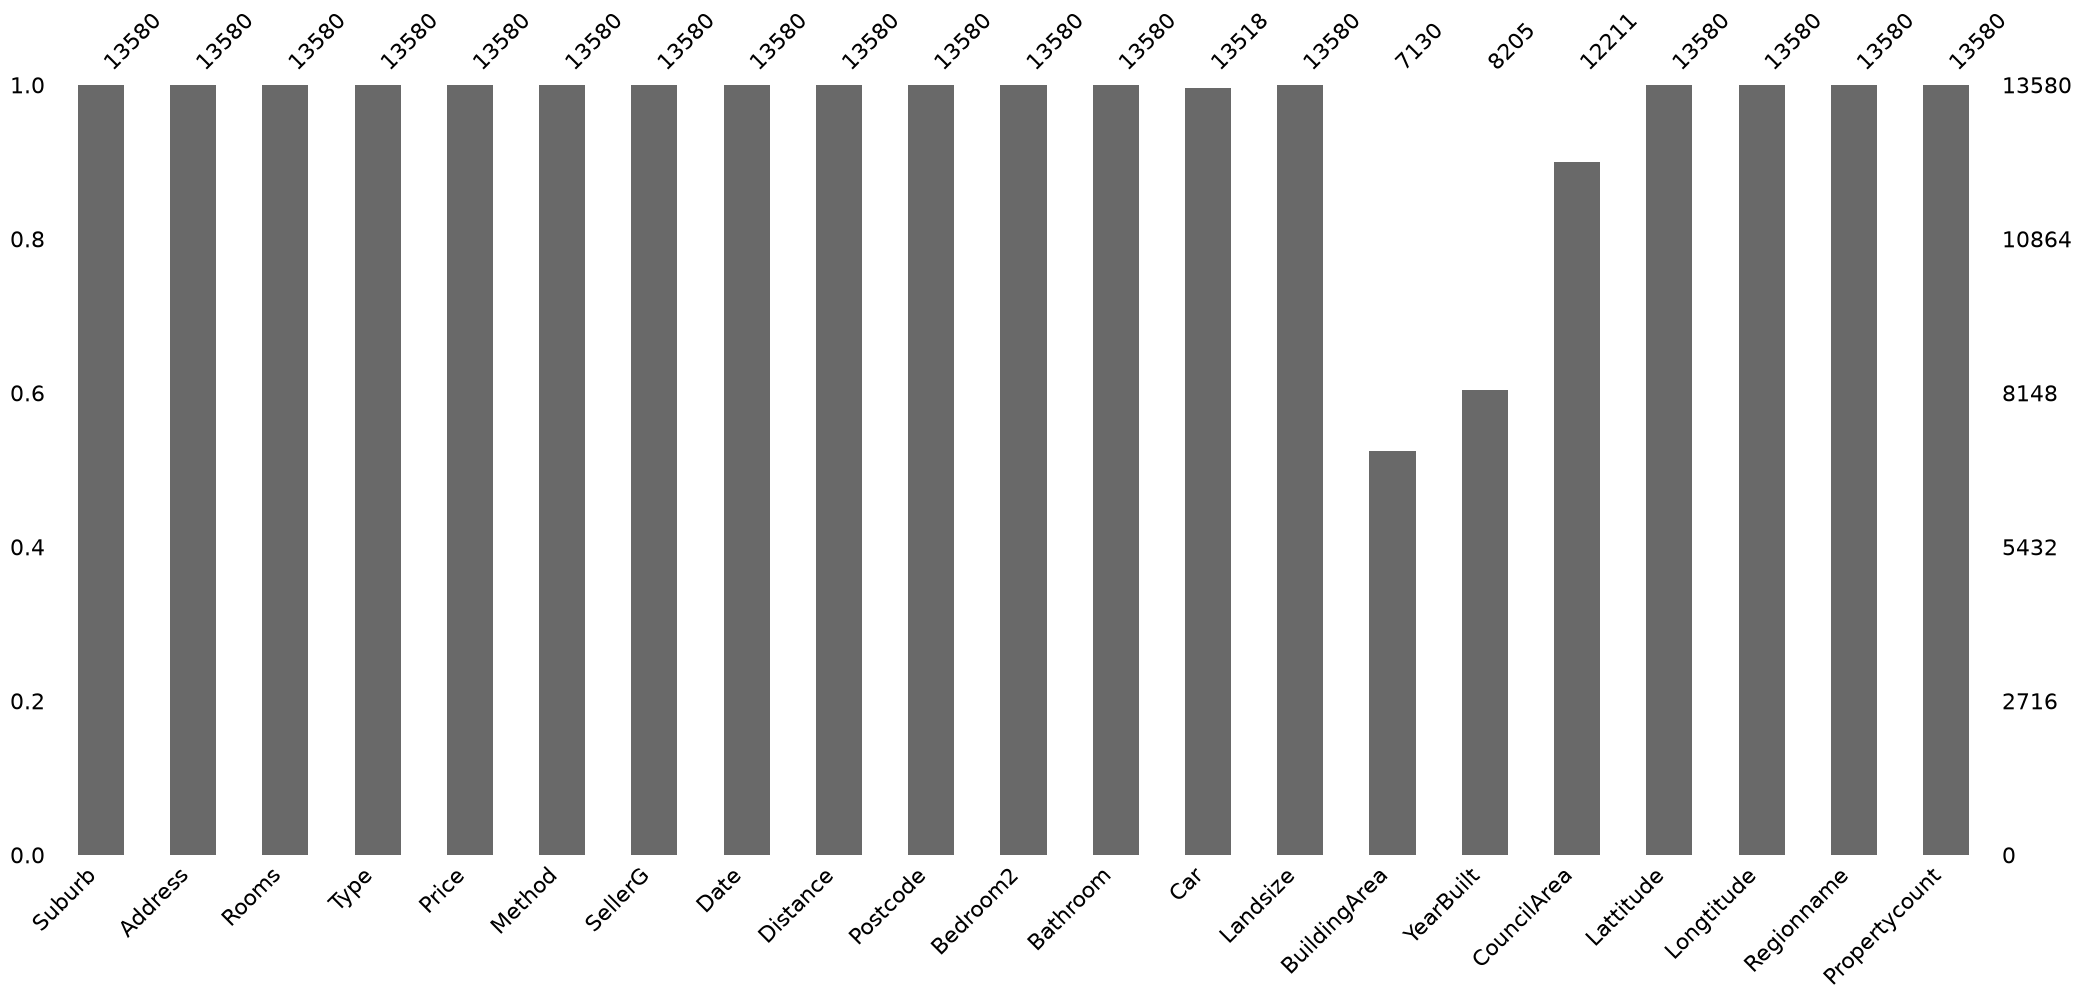


Ausências nas mesmas linhas: 5103


In [8]:
# VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA
msno.matrix(df)
plt.show()

msno.bar(df)
plt.show()

# Verificando se duas colunas possuem valores ausentes juntos
ausencias_juntas = (
    df['BuildingArea'].isnull() &
    df['YearBuilt'].isnull()
).sum()

print("\nAusências nas mesmas linhas:", ausencias_juntas)

In [9]:
# ESTRATÉGIA 1 — REMOÇÃO
df_remocao = df.copy()

# Remove as linhas com valores ausentes
df_remocao = df_remocao.dropna()

print("\nLinhas após remoção:")
print(len(df_remocao))


Linhas após remoção:
6196


In [10]:
# ESTRATÉGIA 2 — IMPUTAÇÃO
df_imputacao = df.copy()

# Preenchendo valores numéricos com a mediana
df_imputacao['BuildingArea'] = df_imputacao['BuildingArea'].fillna(
    df_imputacao['BuildingArea'].median()
)

df_imputacao['YearBuilt'] = df_imputacao['YearBuilt'].fillna(
    df_imputacao['YearBuilt'].median()
)

df_imputacao['Car'] = df_imputacao['Car'].fillna(
    df_imputacao['Car'].median()
)

# Preenchendo a coluna de texto com a moda
df_imputacao['CouncilArea'] = df_imputacao['CouncilArea'].fillna(
    df_imputacao['CouncilArea'].mode()[0]
)

print("\nQuantidade de linhas após imputação:")
print(len(df_imputacao))

print("\nValores ausentes depois da imputação:")
print(df_imputacao.isnull().sum())



Quantidade de linhas após imputação:
13580

Valores ausentes depois da imputação:
Suburb           0
Address          0
Rooms            0
Type             0
Price            0
Method           0
SellerG          0
Date             0
Distance         0
Postcode         0
Bedroom2         0
Bathroom         0
Car              0
Landsize         0
BuildingArea     0
YearBuilt        0
CouncilArea      0
Lattitude        0
Longtitude       0
Regionname       0
Propertycount    0
dtype: int64


Original: 13580
Remoção: 6196
Imputação: 13580

Média original:
BuildingArea     151.967650
YearBuilt       1964.684217
Car                1.610075
dtype: float64

Média após remoção:
BuildingArea     141.568645
YearBuilt       1964.081988
Car                1.573596
dtype: float64

Média após imputação:
BuildingArea     139.633972
YearBuilt       1966.788218
Car                1.611856
dtype: float64

Mediana original:
BuildingArea     126.0
YearBuilt       1970.0
Car                2.0
dtype: float64

Mediana após remoção:
BuildingArea     124.0
YearBuilt       1970.0
Car                1.0
dtype: float64

Mediana após imputação:
BuildingArea     126.0
YearBuilt       1970.0
Car                2.0
dtype: float64


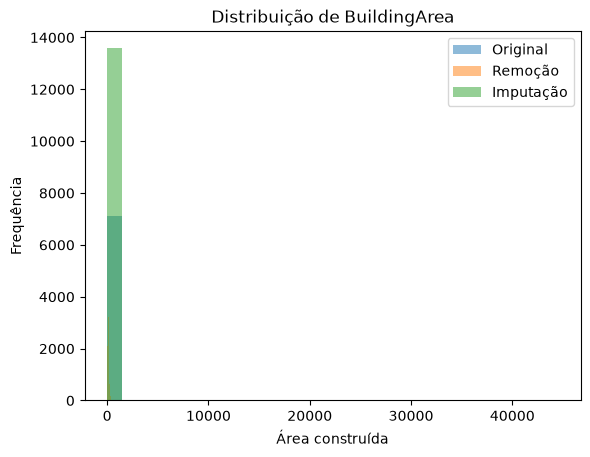

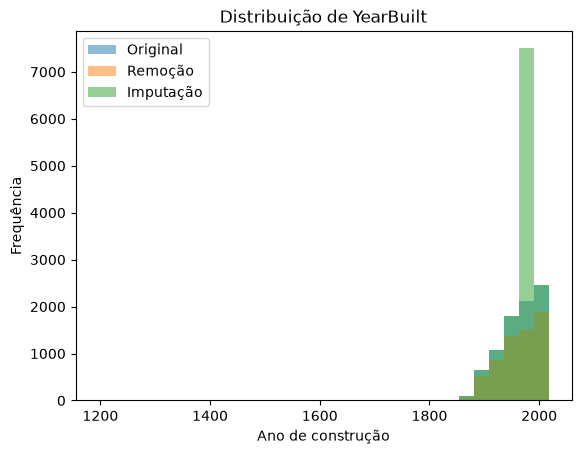

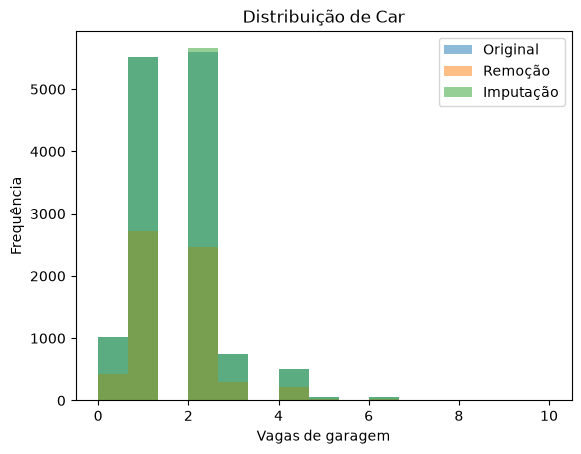


CouncilArea original:
CouncilArea
Moreland         1163
Boroondara       1160
Moonee Valley     997
Darebin           934
Glen Eira         848
Name: count, dtype: int64

CouncilArea após remoção:
CouncilArea
Moreland         658
Boroondara       576
Moonee Valley    504
Darebin          433
Glen Eira        426
Name: count, dtype: int64

CouncilArea após imputação:
CouncilArea
Moreland         2532
Boroondara       1160
Moonee Valley     997
Darebin           934
Glen Eira         848
Name: count, dtype: int64


In [11]:

# COMPARAÇÃO ENTRE AS ESTRATÉGIAS

# Quantidade de linhas
print("Original:", len(df))
print("Remoção:", len(df_remocao))
print("Imputação:", len(df_imputacao))


# Comparando média e mediana das colunas numéricas
colunas = ['BuildingArea', 'YearBuilt', 'Car']

print("\nMédia original:")
print(df[colunas].mean())

print("\nMédia após remoção:")
print(df_remocao[colunas].mean())

print("\nMédia após imputação:")
print(df_imputacao[colunas].mean())


print("\nMediana original:")
print(df[colunas].median())

print("\nMediana após remoção:")
print(df_remocao[colunas].median())

print("\nMediana após imputação:")
print(df_imputacao[colunas].median())


# Comparando a distribuição de BuildingArea
plt.hist(df['BuildingArea'].dropna(), bins=30, alpha=0.5,
         label='Original')

plt.hist(df_remocao['BuildingArea'], bins=30, alpha=0.5,
         label='Remoção')

plt.hist(df_imputacao['BuildingArea'], bins=30, alpha=0.5,
         label='Imputação')

plt.title('Distribuição de BuildingArea')
plt.xlabel('Área construída')
plt.ylabel('Frequência')
plt.legend()
plt.show()


# Comparando a distribuição de YearBuilt
plt.hist(df['YearBuilt'].dropna(), bins=30, alpha=0.5,
         label='Original')

plt.hist(df_remocao['YearBuilt'], bins=30, alpha=0.5,
         label='Remoção')

plt.hist(df_imputacao['YearBuilt'], bins=30, alpha=0.5,
         label='Imputação')

plt.title('Distribuição de YearBuilt')
plt.xlabel('Ano de construção')
plt.ylabel('Frequência')
plt.legend()
plt.show()


# Comparando a distribuição de Car
plt.hist(df['Car'].dropna(), bins=15, alpha=0.5,
         label='Original')

plt.hist(df_remocao['Car'], bins=15, alpha=0.5,
         label='Remoção')

plt.hist(df_imputacao['Car'], bins=15, alpha=0.5,
         label='Imputação')

plt.title('Distribuição de Car')
plt.xlabel('Vagas de garagem')
plt.ylabel('Frequência')
plt.legend()
plt.show()


# Comparando CouncilArea
print("\nCouncilArea original:")
print(df['CouncilArea'].value_counts().head())

print("\nCouncilArea após remoção:")
print(df_remocao['CouncilArea'].value_counts().head())

print("\nCouncilArea após imputação:")
print(df_imputacao['CouncilArea'].value_counts().head())


In [ ]:
# RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO
# 1. As ausências se concentram em poucas colunas?
# Sim. As colunas BuildingArea e YearBuilt apresentam
# as maiores quantidades de valores ausentes.

# 2. As ausências aparecem nas mesmas linhas?
# Algumas ausências podem ocorrer nas mesmas linhas.
# A quantidade foi calculada no código.

# 3. Por que foi utilizada a remoção?
# Para retirar linhas que possuem dados faltantes.
# Porém, isso faz perder uma grande quantidade de registros.

# 4. Por que foi utilizada a imputação?
# Para preencher os valores ausentes sem perder linhas.
# Foi utilizada a mediana para os valores numéricos
# e a moda para a coluna de texto.

# 5. Qual estratégia foi mais adequada?
# A imputação foi mais adequada para preservar os registros.
# A remoção eliminou muitas linhas do conjunto de dados.
# Porém, preencher valores com a mediana também pode
# modificar a distribuição dos dados.
